# Replication script for the paper "Generating Abstract Tests for Asmeta Models by Using Code Transformations and EvoSuite"

This script is used to replicate the results of the analyses presented in the paper.

In [24]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
from IPython.display import display

DATA_FILE = Path('data.csv')
MODEL_LIST_FILE = Path('model_list.txt')
MODEL_LISTS_DIR = Path('model_lists')
VALID_MODEL_LIST_FILE = MODEL_LISTS_DIR / 'model_list_all_valid.txt'
IMAGE_DIR = Path('images')
VALID_STATUSES = {'OK', 'MUTATION_ERR'}
INITIAL_CONFIGURATIONS = ['random', 'atgt', 'evoavalla_budget_60']
ANALYSIS_CONFIGURATIONS = [
    'evoavalla_budget_60', 'atgt', 'random4evoavalla_budget_60', 'random4atgt'
]
ALL_CONFIGURATIONS = list(dict.fromkeys(INITIAL_CONFIGURATIONS + ANALYSIS_CONFIGURATIONS))

def model_key(path):
    path = str(path).strip().replace('\\', '/')
    if 'asm_examples/' in path:
        path = path.split('asm_examples/', 1)[1]
    return path.removeprefix('./')

# Ignore blank lines and comments; preserve the order and spelling of model_list.txt.
model_list = [
    line.split('//', 1)[0].strip()
    for line in MODEL_LIST_FILE.read_text(encoding='utf-8-sig').splitlines()
    if line.split('//', 1)[0].strip()
]
model_keys = list(dict.fromkeys(model_key(model) for model in model_list))
df = pd.read_csv(DATA_FILE)
# The CSV calls its configuration field 'approach'; use distinct names in this notebook.
df = df.rename(columns={'approach': 'configuration'})
df['model_spec'] = df['asm_path'].map(model_key)
df['is_valid'] = df['status'].isin(VALID_STATUSES)
# Ignore all configurations outside the scope of this analysis.
df = df[df['configuration'].isin(ALL_CONFIGURATIONS)].copy()

# Each configuration/specification pair has exactly one CSV record.
# Records outside model_list.txt are excluded from RQ1, RQ2, RQ3, RQ4, plots, statistical tests,
# and model_list_all_valid.txt.
study_df = df[df['model_spec'].isin(model_keys) & df['configuration'].isin(ALL_CONFIGURATIONS)].copy()
validity = (
    study_df.pivot(index='model_spec', columns='configuration', values='is_valid')
    .reindex(index=model_keys, columns=ALL_CONFIGURATIONS)
    .fillna(False).astype(bool)
)
print(f'Specifications in model_list.txt: {len(model_keys)}')
outside_model_list = df.loc[~df['model_spec'].isin(model_keys)]
print(f'CSV records outside model_list.txt: {len(outside_model_list)}')
print(f'Distinct specifications outside model_list.txt: {outside_model_list["model_spec"].nunique()}')
for specification in sorted(outside_model_list['model_spec'].unique()):
    print(f'  {specification}')
missing = [a for a in ALL_CONFIGURATIONS if a not in set(study_df['configuration'])]
print(f'Configurations not yet present: {missing}')


Specifications in model_list.txt: 295
CSV records outside model_list.txt: 25
Distinct specifications outside model_list.txt: 13
  examples/GilbreathCardTrick/GilbreathCardTrickForAsmetaSMV_flat.asm
  examples/GilbreathCardTrick/GilbreathCardTrick_flat.asm
  examples/RushHour/RushHour_flat.asm
  examples/coffeeVendingMachine/coffeeVendingMachine_flat.asm
  examples/conwayGameOfLife/gameOfLifeAgents_flat.asm
  examples/conwayGameOfLife/gameOfLife_flat.asm
  examples/hemodialysisDevice/SCP2017/HemodialysisRef3_flat.asm
  examples/landingGearSystem/LGS_3L_flat.asm
  examples/petriNets/forAsmetaSMV/petriNet_forNuSMV_flat.asm
  examples/philosophers/philosophers3_flat.asm
  examples/roulette/roulette_flat.asm
  examples/simple_example/AdvancedClockDeciSecond.asm
  examples/ticTacToe/ticTacToe_simulator_flat.asm
Configurations not yet present: []


C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\2480435802.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False).astype(bool)


## Check initial configuration records

Check that every active specification in `model_list.txt` has a CSV record for Random, ATGT and EvoAvalla. This checks record presence regardless of generation status: an unsuccessful generation still counts as a present record. Report missing configuration/specification pairs; the analysis can continue with missing records treated as invalid.


In [25]:
expected_pairs = pd.MultiIndex.from_product(
    [INITIAL_CONFIGURATIONS, model_keys], names=['configuration', 'model_spec']
)
present_pairs = pd.MultiIndex.from_frame(
    study_df.loc[study_df['configuration'].isin(INITIAL_CONFIGURATIONS),
                 ['configuration', 'model_spec']]
)
missing_pairs = expected_pairs.difference(present_pairs, sort=False).to_frame(index=False)
missing_counts = missing_pairs.groupby('configuration').size().reindex(
    INITIAL_CONFIGURATIONS, fill_value=0
)
record_check = pd.DataFrame({
    'expected_records': len(model_keys),
    'present_records': len(model_keys) - missing_counts,
    'missing_records': missing_counts,
})
display(record_check)
if missing_pairs.empty:
    print('PASS: every listed specification has a record for all three initial configurations.')
else:
    print(f'MISSING: {len(missing_pairs)} configuration/specification pairs across '
          f'{missing_pairs["model_spec"].nunique()} distinct specifications.')
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
        display(missing_pairs)


,expected_records,present_records,missing_records
configuration,,,
random,295,295,0
atgt,295,295,0
evoavalla_budget_60,295,295,0


PASS: every listed specification has a record for all three initial configurations.


## RQ1: Valid test generation

Use only `random` (the fixed-size baseline), `atgt` and `evoavalla_budget_60`. Report available specifications, valid specifications, and specifications where only that approach is valid (`only_approach_valid`). For each pair, report inclusive and exclusive intersections relative to these three approaches. Finally report the intersection of all three, the number valid for at least one, and the count where none is valid.

All counts refer to active specifications in `model_list.txt`; missing records count as invalid. Valid statuses are `OK` and `MUTATION_ERR`.


In [26]:
initial_df = study_df[study_df['configuration'].isin(INITIAL_CONFIGURATIONS)]
initial_validity = validity[INITIAL_CONFIGURATIONS]
initial_all_valid_models = initial_validity.index[initial_validity.all(axis=1)]

rq1_summary = initial_df.groupby('configuration').agg(
    specifications=('configuration', 'size'),
    valid_specifications=('is_valid', 'sum'),
).reindex(INITIAL_CONFIGURATIONS, fill_value=0)
rq1_summary['only_approach_valid'] = [
    int((initial_validity[c] & ~initial_validity[
        [other for other in INITIAL_CONFIGURATIONS if other != c]
    ].any(axis=1)).sum())
    for c in INITIAL_CONFIGURATIONS
]
display(rq1_summary)

pair_counts = []
for left, right in combinations(INITIAL_CONFIGURATIONS, 2):
    both = initial_validity[left] & initial_validity[right]
    others = [c for c in INITIAL_CONFIGURATIONS if c not in (left, right)]
    pair_counts.append({
        'configuration_1': left, 'configuration_2': right,
        'both_valid': int(both.sum()),
        'exclusive_intersection': int((both & ~initial_validity[others].any(axis=1)).sum()),
    })
display(pd.DataFrame(pair_counts))
print(f'Valid for all three approaches: {len(initial_all_valid_models)}')
print(f'Valid for at least one approach: {int(initial_validity.any(axis=1).sum())}')
print(f'No approach valid: {int((~initial_validity.any(axis=1)).sum())}')


,specifications,valid_specifications,only_approach_valid
configuration,,,
random,295,174,80
atgt,295,51,0
evoavalla_budget_60,295,97,5


,configuration_1,configuration_2,both_valid,exclusive_intersection
0,random,atgt,50,3
1,random,evoavalla_budget_60,91,44
2,atgt,evoavalla_budget_60,48,1


Valid for all three approaches: 47
Valid for at least one approach: 180
No approach valid: 115


## Utility: Export valid specification lists

Create `model_lists/` and write `model_list_all_valid.txt` using the intersection of Random (the fixed-size baseline), ATGT and EvoAvalla budget 60 from RQ1. Also write `model_list_<configuration>_valid.txt` only for these three configurations when available. Keep specifications from `model_list.txt` in their original order and path format; valid statuses are `OK` and `MUTATION_ERR`. Skip unavailable configurations; skip the common-list export if an initial configuration is entirely missing.


In [27]:
MODEL_LISTS_DIR.mkdir(exist_ok=True)

def export_model_list(path, valid_models):
    valid_models = set(valid_models)
    models = [m for m in model_list if model_key(m) in valid_models]
    path.write_text('\n'.join(models) + ('\n' if models else ''), encoding='utf-8')
    print(f'Wrote {len(models)} specifications to {path}')
    return models

missing_initial = [a for a in INITIAL_CONFIGURATIONS if a not in set(initial_df['configuration'])]
valid_model_list = []
if missing_initial:
    print(f'Common-list export skipped; missing initial configurations: {missing_initial}')
else:
    valid_model_list = export_model_list(VALID_MODEL_LIST_FILE, initial_all_valid_models)

for configuration in INITIAL_CONFIGURATIONS:
    if configuration not in set(study_df['configuration']):
        print(f'Configuration-list export skipped: {configuration} has no records.')
        continue
    valid_models = validity.index[validity[configuration]]
    export_model_list(
        MODEL_LISTS_DIR / f'model_list_{configuration}_valid.txt', valid_models
    )


Wrote 47 specifications to model_lists\model_list_all_valid.txt
Wrote 174 specifications to model_lists\model_list_random_valid.txt
Wrote 51 specifications to model_lists\model_list_atgt_valid.txt
Wrote 97 specifications to model_lists\model_list_evoavalla_budget_60_valid.txt


## Data preparation for RQ2, RQ3 and RQ4

We use EvoAvalla budget 60, ATGT, Random_EA (`random4evoavalla_budget_60`) and Random_ATGT (`random4atgt`). Random_EA and Random_ATGT are two configurations of the Random approach. They remain separate in plots and tests.

Start from the RQ1 common-valid set exported to `model_lists/model_list_all_valid.txt`, and retain specifications with valid results for all four selected configurations.

In [28]:
PLOT_LABELS = dict(zip(
    ANALYSIS_CONFIGURATIONS, ['EvoAvalla', 'ATGT', 'Random_EA', 'Random_ATGT']
))
PLOT_ORDER = list(PLOT_LABELS.values())
PALETTE = ['#ea96a3', '#98a247', '#4aaba4', '#b6a8eb']
selected_validity = validity.loc[initial_all_valid_models, ANALYSIS_CONFIGURATIONS]
common_valid_models = selected_validity.index[selected_validity.all(axis=1)]
common_df = study_df[
    study_df['model_spec'].isin(common_valid_models)
    & study_df['configuration'].isin(ANALYSIS_CONFIGURATIONS)
    & study_df['is_valid']
].copy()
common_df['plot_configuration'] = common_df['configuration'].map(PLOT_LABELS)
analysis_ready = not common_df.empty
print(f'Common valid specifications for RQ2, RQ3 and RQ4: {len(common_valid_models)}')
print(f'RQ1 common specifications excluded for missing/invalid selected configurations: '
      f'{len(initial_all_valid_models) - len(common_valid_models)}')
missing_analysis = [c for c in ANALYSIS_CONFIGURATIONS if c not in set(study_df['configuration'])]
if missing_analysis:
    print(f'RQ2, RQ3 and RQ4 skipped; missing configurations: {missing_analysis}')
elif not analysis_ready:
    print('RQ2, RQ3 and RQ4 skipped: no common valid specifications yet.')

COVERAGE_TYPES = ['branch_coverage', 'rule_coverage', 'update_rule_coverage', 'macro_coverage']
SIZE_METRICS = ['n_scenarios', 'n_step']
MUTATION_COLUMNS = [
    'casemutator_score', 'ruleremover_score', 'chooserulemutator_score',
    'condnegator_score', 'forallmutator_score', 'partoseqmutator_score',
    'seqtoparmutator_score', 'condremover_score',
]
if analysis_ready:
    numeric_columns = ['exec_time_ms'] + SIZE_METRICS + COVERAGE_TYPES + MUTATION_COLUMNS
    common_df[numeric_columns] = common_df[numeric_columns].apply(pd.to_numeric, errors='raise')
    # Average the available operator scores per execution.
    # An execution with all operator scores missing keeps mutation_score = NaN.
    common_df['mutation_score'] = common_df[MUTATION_COLUMNS].mean(axis=1, skipna=True)



Common valid specifications for RQ2, RQ3 and RQ4: 47
RQ1 common specifications excluded for missing/invalid selected configurations: 0


## Statistical analysis and plot formatting

Report mean and sample standard deviation; tables also include count and sample variance. Use two-sided Wilcoxon signed-rank tests, paired by specification. Report the statistic, number of complete pairs, and p-value. A p-value <= 0.05 is labelled "Significant difference".

In [29]:
REFERENCE_COMPARISONS = [
    ('EvoAvalla', 'ATGT'),
    ('Random_EA', 'ATGT'),
    ('Random_ATGT', 'ATGT'),
    ('EvoAvalla', 'Random_EA'),
    ('Random_ATGT', 'EvoAvalla'),
]

def descriptive_stats(data, metrics, order=PLOT_ORDER):
    return (
        data.groupby('plot_configuration')[metrics]
        .agg(['count', 'mean', 'var', 'std'])
        .reindex(order).rename_axis('configuration')
    )

def wilcoxon_table(data, metrics, comparisons=REFERENCE_COMPARISONS):
    results = []
    for metric in metrics:
        values = data.pivot(index='model_spec', columns='plot_configuration', values=metric)
        for left, right in comparisons:
            pairs = values[[left, right]].dropna()
            differences = pairs[left] - pairs[right]
            if pairs.empty:
                statistic, p_value = float('nan'), float('nan')
                result = 'Not testable'
            elif (differences == 0).all():
                statistic, p_value = float('nan'), 1.0
                result = 'Identical observed values'
            else:
                test = wilcoxon(pairs[left], pairs[right], alternative='two-sided', nan_policy='omit')
                statistic, p_value = test.statistic, test.pvalue
                result = 'Not significant'
                if p_value <= 0.05:
                    # Use the direction of Wilcoxon's signed ranks, excluding zero differences.
                    nonzero_differences = differences[differences != 0]
                    ranks = nonzero_differences.abs().rank()
                    positive_ranks = ranks[nonzero_differences > 0].sum()
                    negative_ranks = ranks[nonzero_differences < 0].sum()
                    if positive_ranks > negative_ranks:
                        result = f'Significant difference: {left} > {right}'
                    else:
                        result = f'Significant difference: {right} > {left}'
            results.append({
                'metric': metric, 'left': left, 'right': right, 'pairs': len(pairs),
                'statistic': statistic, 'p_value': p_value, 'result': result,
            })
    table = pd.DataFrame(results)
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(table)
    return table

def reference_boxplot(data, metric, size=False, time=False):
    sns.set(style='whitegrid')
    plt.figure(figsize=(1.6, 3.7) if size else (2, 3))
    order = ['EvoAvalla', 'ATGT'] if size else PLOT_ORDER
    palette = PALETTE[:2] if size else PALETTE
    sns.boxplot(x='plot_configuration', y=metric, data=data,
                order=order, palette=palette, showfliers=False)
    plt.xlabel('')
    if time:
        plt.yscale('log')
        plt.ylabel('Time [ms]')
    else:
        plt.ylabel('')
        if not size:
            plt.ylim(0, 1.01)
    plt.tight_layout()
    plt.xticks(rotation=90)
    if size:
        plt.yticks(rotation=90)
    IMAGE_DIR.mkdir(exist_ok=True)
    plt.savefig(IMAGE_DIR / f'boxplot_{metric}.pdf', bbox_inches='tight')
    plt.show()
    plt.close()


## RQ2: Test generation time

Compare `exec_time_ms` for EvoAvalla budget 60, ATGT, Random_EA and Random_ATGT. Report the descriptive measures and the five Wilcoxon comparisons.

exec_time_ms                                         
                     count          mean           var          std
configuration                                                      
EvoAvalla               47  68671.063830  1.913021e+07  4373.809450
ATGT                    47   1455.446809  7.965062e+06  2822.244218
Random_EA               47     17.382979  1.549372e+03    39.362061
Random_ATGT             47     41.468085  8.742515e+03    93.501419

,metric,left,right,pairs,statistic,p_value,result
0,exec_time_ms,EvoAvalla,ATGT,47,0.0,2.396218e-09,Significant difference: EvoAvalla > ATGT
1,exec_time_ms,Random_EA,ATGT,47,0.0,2.396218e-09,Significant difference: ATGT > Random_EA
2,exec_time_ms,Random_ATGT,ATGT,47,0.0,2.395605e-09,Significant difference: ATGT > Random_ATGT
3,exec_time_ms,EvoAvalla,Random_EA,47,0.0,1.421085e-14,Significant difference: EvoAvalla > Random_EA
4,exec_time_ms,Random_ATGT,EvoAvalla,47,0.0,1.421085e-14,Significant difference: EvoAvalla > Random_ATGT


C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


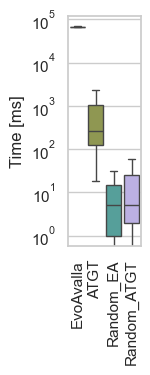

In [30]:
rq2_tests = pd.DataFrame()
if analysis_ready:
    display(descriptive_stats(common_df, ['exec_time_ms']))
    rq2_tests = wilcoxon_table(common_df, ['exec_time_ms'])
    reference_boxplot(common_df, 'exec_time_ms', time=True)


## RQ3: Size of test suites

Compare EvoAvalla budget 60 and ATGT for number of tests (`n_scenarios`) and steps (`n_step`).

n_scenarios                                    n_step  \
                    count       mean          var        std  count   
configuration                                                         
EvoAvalla              47   8.680851   194.265495  13.937916     47   
ATGT                   47  22.191489  1132.853839  33.657894     47   

                                                      
                     mean            var         std  
configuration                                         
EvoAvalla       24.340426    1107.490287   33.278977  
ATGT           167.297872  282482.170213  531.490518

,metric,left,right,pairs,statistic,p_value,result
0,n_scenarios,EvoAvalla,ATGT,47,41.0,1.124774e-07,Significant difference: ATGT > EvoAvalla
1,n_step,EvoAvalla,ATGT,47,18.0,7.529452e-09,Significant difference: ATGT > EvoAvalla


C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


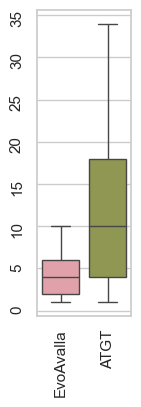

C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


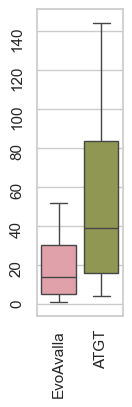

In [31]:
rq3_tests = pd.DataFrame()
if analysis_ready:
    size_df = common_df[common_df['plot_configuration'].isin(['EvoAvalla', 'ATGT'])]
    display(descriptive_stats(size_df, SIZE_METRICS, order=['EvoAvalla', 'ATGT']))
    rq3_tests = wilcoxon_table(size_df, SIZE_METRICS, comparisons=[('EvoAvalla', 'ATGT')])
    for metric in SIZE_METRICS:
        reference_boxplot(size_df, metric, size=True)


## RQ4: Coverage

For branch, rule, update-rule and macro coverage, report descriptive measures and the five two-sided paired Wilcoxon comparisons.

EvoAvalla vs Random_EA and Random_ATGT vs ATGT compare the configurations intended to have matching suite sizes.

branch_coverage                               rule_coverage  \
                        count      mean       var       std         count   
configuration                                                               
EvoAvalla                  47  0.890854  0.026931  0.164108            47   
ATGT                       47  0.968604  0.002986  0.054641            47   
Random_EA                  47  0.627446  0.055953  0.236543            47   
Random_ATGT                47  0.781740  0.042917  0.207164            47   

                                            update_rule_coverage            \
                   mean       var       std                count      mean   
configuration                                                                
EvoAvalla      0.943404  0.018384  0.135588                   47  0.845133   
ATGT           0.986650  0.001648  0.040598                   47  0.939686   
Random_EA      0.603340  0.049729  0.223000                   47  0.433605   
Random_ATGT    0.762196  0.041659  0.204104                   47  0.653992   

                                  macro_coverage                                
                    var       std          count      mean       var       std  
configuration                                                                   
EvoAvalla      0.035235  0.187710             47  0.973624  0.009855  0.099271  
ATGT           0.010684  0.103363             47  0.997636  0.000263  0.016207  
Random_EA      0.051505  0.226948             47  0.795743  0.060908  0.246795  
Random_ATGT    0.065936  0.256781             47  0.883711  0.031039  0.176178

,metric,left,right,pairs,statistic,p_value,result
0,branch_coverage,EvoAvalla,ATGT,47,45.5,3.341031e-04,Significant difference: ATGT > EvoAvalla
1,branch_coverage,Random_EA,ATGT,47,0.0,2.413589e-08,Significant difference: ATGT > Random_EA
2,branch_coverage,Random_ATGT,ATGT,47,0.0,5.355264e-07,Significant difference: ATGT > Random_ATGT
3,branch_coverage,EvoAvalla,Random_EA,47,0.0,7.694356e-08,Significant difference: EvoAvalla > Random_EA
4,branch_coverage,Random_ATGT,EvoAvalla,47,88.0,9.944482e-04,Significant difference: EvoAvalla > Random_ATGT
5,rule_coverage,EvoAvalla,ATGT,47,33.0,7.027882e-02,Not significant
6,rule_coverage,Random_EA,ATGT,47,0.0,7.604826e-09,Significant difference: ATGT > Random_EA
7,rule_coverage,Random_ATGT,ATGT,47,0.0,2.475883e-07,Significant difference: ATGT > Random_ATGT
8,rule_coverage,EvoAvalla,Random_EA,47,0.0,1.118790e-08,Significant difference: EvoAvalla > Random_EA
9,rule_coverage,Random_ATGT,EvoAvalla,47,43.0,1.353808e-05,Significant difference: EvoAvalla > Random_ATGT


C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


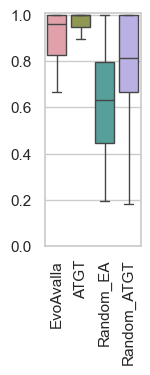

C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


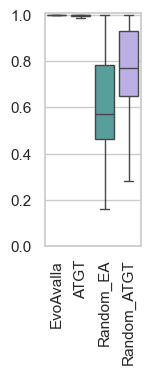

C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


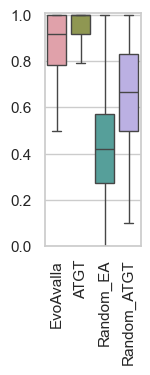

C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


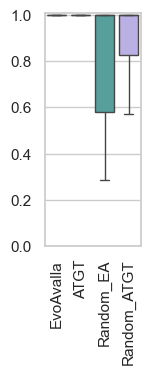

In [32]:
rq4_coverage_tests = pd.DataFrame()
if analysis_ready:
    display(descriptive_stats(common_df, COVERAGE_TYPES))
    rq4_coverage_tests = wilcoxon_table(common_df, COVERAGE_TYPES)
    for coverage in COVERAGE_TYPES:
        reference_boxplot(common_df, coverage)


## RQ4: Mutation score

Calculate each execution's mutation score as the mean of its available mutation-operator scores. Report descriptive measures and the five two-sided paired Wilcoxon comparisons.

mutation_score                              
                       count      mean       var       std
configuration                                             
EvoAvalla                 47  0.658316  0.057948  0.240724
ATGT                      47  0.703787  0.014881  0.121987
Random_EA                 47  0.515728  0.043876  0.209467
Random_ATGT               47  0.636087  0.034303  0.185211

,metric,left,right,pairs,statistic,p_value,result
0,mutation_score,EvoAvalla,ATGT,47,348.0,4.046043e-01,Not significant
1,mutation_score,Random_EA,ATGT,47,71.0,7.488527e-07,Significant difference: ATGT > Random_EA
2,mutation_score,Random_ATGT,ATGT,47,188.0,1.675678e-03,Significant difference: ATGT > Random_ATGT
3,mutation_score,EvoAvalla,Random_EA,47,171.0,1.560296e-04,Significant difference: EvoAvalla > Random_EA
4,mutation_score,Random_ATGT,EvoAvalla,47,241.0,3.759027e-02,Significant difference: EvoAvalla > Random_ATGT


C:\Users\nicop\AppData\Local\Temp\ipykernel_34284\1368314711.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='plot_configuration', y=metric, data=data,


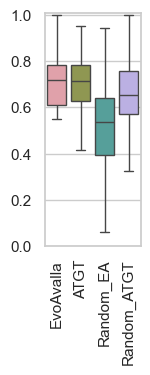

In [33]:
rq4_mutation_tests = pd.DataFrame()
if analysis_ready:
    display(descriptive_stats(common_df, ['mutation_score']))
    rq4_mutation_tests = wilcoxon_table(common_df, ['mutation_score'])
    reference_boxplot(common_df, 'mutation_score')
